# Cây Quyết Định (Decision Tree - Thuật toán CART)

Khác với các mô hình tuyến tính sử dụng phương trình toán học để vẽ đường thẳng/cong, Cây quyết định phân chia không gian dữ liệu bằng hàng loạt các **câu hỏi Yes/No** lồng nhau. Ranh giới quyết định tạo ra luôn vuông góc với các trục tọa độ (Orthogonal Boundaries).

**1. Tiêu chí phân chia (Splitting Criteria):**
Mục tiêu là tìm ra đặc trưng (feature) và ngưỡng (threshold) sao cho sau khi cắt, dữ liệu ở 2 nhánh con trở nên "tinh khiết" nhất (chứa nhiều mẫu cùng 1 lớp nhất). Độ hỗn loạn được đo bằng:
*   **Entropy:** $H(S) = -\sum_{c=1}^C p_c \log_2(p_c)$
*   **Gini Impurity:** $Gini(S) = 1 - \sum_{c=1}^C p_c^2$
*(Trong đó $p_c$ là tỷ lệ số mẫu thuộc lớp $c$ trong tập $S$)*

**2. Information Gain (Mức tăng thông tin):**
Mức độ giảm sự hỗn loạn sau khi chia tập $S$ gốc thành 2 tập con $S_{left}$ và $S_{right}$:
$$IG = H(S) - \left( \frac{|S_{left}|}{|S|} H(S_{left}) + \frac{|S_{right}|}{|S|} H(S_{right}) \right)$$
Thuật toán (Greedy) sẽ duyệt qua tất cả các đặc trưng và tất cả các giá trị có thể có để tìm ra điểm chia mang lại $IG$ cao nhất.

**3. Điều kiện dừng (Stopping Criteria):**
Để tránh Overfitting (cây mọc quá sâu, ghi nhớ từng điểm nhiễu), ta cần giới hạn: Độ sâu tối đa (max_depth), số mẫu tối thiểu để tiếp tục chia (min_samples_split), hoặc dừng khi nhánh con đã tinh khiết 100% (Entropy = 0).

In [3]:
import numpy as np
from collections import Counter

class Node:
    """Nút của Cây quyết định lưu trữ logic phân chia."""
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature       # Chỉ số đặc trưng dùng để cắt (ví dụ: cột 0)
        self.threshold = threshold   # Ngưỡng giá trị cắt
        self.left = left             # Nhánh con trái (Node)
        self.right = right           # Nhánh con phải (Node)
        self.value = value           # Nhãn phân loại nếu đây là nút lá (Leaf)
        
    def is_leaf(self):
        return self.value is not None

class DecisionTreeScratch:
    """Thuật toán CART phân loại xây dựng bằng Đệ quy."""
    def __init__(self, min_samples_split=2, max_depth=100):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.root = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        X, y = np.asarray(X), np.asarray(y)
        self.root = self._grow_tree(X, y)
        return self

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        n_labels = len(np.unique(y))

        # Điều kiện dừng (Stopping criteria)
        if (depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split):
            leaf_value = self._most_common_label(y)
            return Node(value=leaf_value)

        # Duyệt tìm điểm chia tốt nhất (Greedy Search)
        best_feat, best_thresh = self._best_split(X, y, n_features)

        if best_feat is None:
            return Node(value=self._most_common_label(y))

        # Tách tập dữ liệu
        left_idxs, right_idxs = self._split(X[:, best_feat], best_thresh)
        left_node = self._grow_tree(X[left_idxs, :], y[left_idxs], depth + 1)
        right_node = self._grow_tree(X[right_idxs, :], y[right_idxs], depth + 1)
        
        return Node(best_feat, best_thresh, left_node, right_node)

    def _best_split(self, X, y, n_features):
        best_gain = -1
        split_idx, split_thresh = None, None
        for feat_idx in range(n_features):
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)
            for thr in thresholds:
                gain = self._information_gain(y, X_column, thr)
                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = thr
        return split_idx, split_thresh

    def _information_gain(self, y, X_column, threshold):
        parent_entropy = self._entropy(y)
        left_idxs, right_idxs = self._split(X_column, threshold)
        
        if len(left_idxs) == 0 or len(right_idxs) == 0:
            return 0
            
        n = len(y)
        e_l, e_r = self._entropy(y[left_idxs]), self._entropy(y[right_idxs])
        child_entropy = (len(left_idxs) / n) * e_l + (len(right_idxs) / n) * e_r
        
        return parent_entropy - child_entropy

    def _split(self, X_column, split_thresh):
        left_idxs = np.argwhere(X_column <= split_thresh).flatten()
        right_idxs = np.argwhere(X_column > split_thresh).flatten()
        return left_idxs, right_idxs

    def _entropy(self, y):
        hist = np.bincount(y)
        ps = hist / len(y)
        return -np.sum([p * np.log2(p) for p in ps if p > 0])

    def _most_common_label(self, y):
        return Counter(y).most_common(1)[0][0]

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def _traverse_tree(self, x, node):
        if node.is_leaf():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)

In [4]:
# import time
# import numpy as np
# import matplotlib.pyplot as plt
# from sklearn.tree import DecisionTreeClassifier
# from sklearn.datasets import make_classification
# from utils.metrics import accuracy_score
# from utils.preprocessing import train_test_split

# # 1. Sinh dữ liệu (Decision Tree không yêu cầu chuẩn hóa StandardScaler)
# X, y = make_classification(n_samples=300, n_features=2, n_informative=2, 
#                            n_redundant=0, n_classes=2, random_state=42, cluster_std=1.2)
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# # 2. Huấn luyện model Scratch (Giới hạn độ sâu để tránh Overfitting)
# t0 = time.time()
# model_scratch = DecisionTreeScratch(max_depth=5).fit(X_train, y_train)
# t_scratch = (time.time() - t0) * 1000

# # 3. Huấn luyện model Sklearn
# t0 = time.time()
# model_sklearn = DecisionTreeClassifier(max_depth=5, criterion='entropy', random_state=42).fit(X_train, y_train)
# t_sklearn = (time.time() - t0) * 1000

# # 4. Đánh giá
# y_pred_scratch = model_scratch.predict(X_test)
# y_pred_sklearn = model_sklearn.predict(X_test)

# print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn':<15}")
# print("-" * 55)
# print(f"{'Accuracy Score':<20} | {accuracy_score(y_test, y_pred_scratch):<15.4f} | {accuracy_score(y_test, y_pred_sklearn):<15.4f}")
# print(f"{'Time (ms)':<20} | {t_scratch:<15.2f} | {t_sklearn:<15.2f}")

# # 5. Trực quan hóa ranh giới phân chia (Orthogonal Boundaries)
# plt.figure(figsize=(9, 6))

# x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
# y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
# xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# Z = model_scratch.predict(np.c_[xx.ravel(), yy.ravel()])
# Z = Z.reshape(xx.shape)

# plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
# plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', alpha=0.8)
# plt.title("Ranh giới phân loại hình Bậc thang (Orthogonal) của Decision Tree")
# plt.xlabel("Đặc trưng 1")
# plt.ylabel("Đặc trưng 2")

# plt.tight_layout()
# plt.show()

# Lỗi sẽ xảy ra do hàm make_classification của thư viện Scikit-Learn không hỗ trợ tham số cluster_std (đây là tham số dành riêng cho hàm make_blobs mà chúng ta đã sử dụng ở các thuật toán trước)
#Cách fix: cluster_std bằng tham số class_sep=0.8

Metric               | Scratch         | Sklearn        
-------------------------------------------------------
Accuracy Score       | 0.9167          | 0.9333         
Time (ms)            | 75.34           | 4.98           


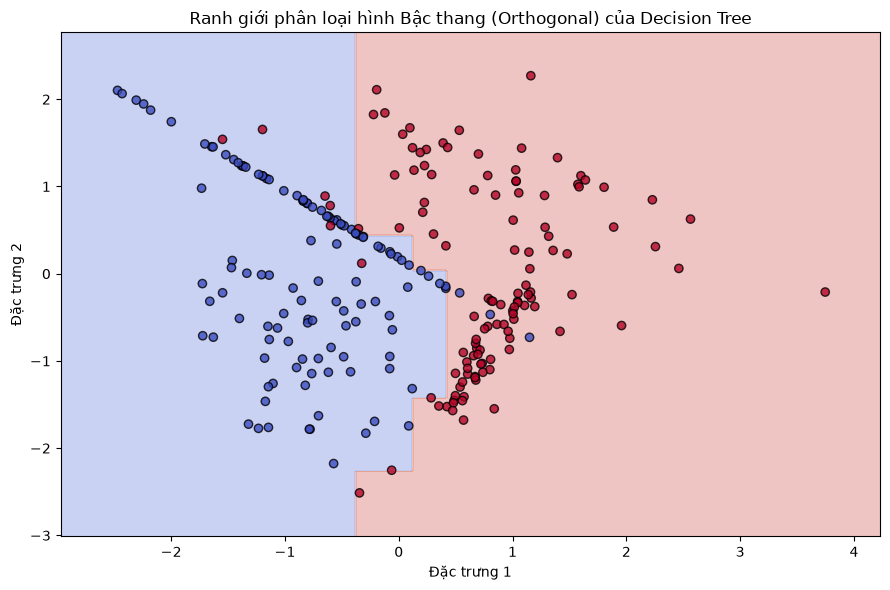

In [5]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_classification
from utils.metrics import accuracy_score
from utils.preprocessing import train_test_split

# 1. Sinh dữ liệu (Đã loại bỏ tham số cluster_std không hợp lệ)
X, y = make_classification(n_samples=300, n_features=2, n_informative=2, 
                           n_redundant=0, n_classes=2, random_state=42, class_sep=0.8)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Huấn luyện model Scratch (Giới hạn độ sâu để tránh Overfitting)
t0 = time.time()
model_scratch = DecisionTreeScratch(max_depth=5).fit(X_train, y_train)
t_scratch = (time.time() - t0) * 1000

# 3. Huấn luyện model Sklearn
t0 = time.time()
model_sklearn = DecisionTreeClassifier(max_depth=5, criterion='entropy', random_state=42).fit(X_train, y_train)
t_sklearn = (time.time() - t0) * 1000

# 4. Đánh giá
y_pred_scratch = model_scratch.predict(X_test)
y_pred_sklearn = model_sklearn.predict(X_test)

print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn':<15}")
print("-" * 55)
print(f"{'Accuracy Score':<20} | {accuracy_score(y_test, y_pred_scratch):<15.4f} | {accuracy_score(y_test, y_pred_sklearn):<15.4f}")
print(f"{'Time (ms)':<20} | {t_scratch:<15.2f} | {t_sklearn:<15.2f}")

# 5. Trực quan hóa ranh giới phân chia (Orthogonal Boundaries)
plt.figure(figsize=(9, 6))

x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = model_scratch.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title("Ranh giới phân loại hình Bậc thang (Orthogonal) của Decision Tree")
plt.xlabel("Đặc trưng 1")
plt.ylabel("Đặc trưng 2")

plt.tight_layout()
plt.show()